# PINN trained on the FD solver output

Stage 1 of the plan: get a physics-informed network to reproduce a known
thermal solution. The FD solver stands in for the FEA until those files
arrive; swapping in real data later means changing only the loading cell.

The network maps position and time to temperature:

$$N\!N(\hat z, \hat t\,; \theta) \approx \hat T(\hat z, \hat t)$$

and is trained against two things at once — the solver's values, and the
heat equation itself.


In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(123)
np.random.seed(123)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cpu


## Load the solver output

In [2]:
d = np.load("data/baseline.npz")
z, ts, Ts = d["z"], d["t"], d["T"]
H, t_end = float(z[-1]), float(ts[-1])
alpha = float(d["alpha"])
T_inf, T_nozzle, Tg, LH = float(d["T_inf"]), float(d["T_nozzle"]), float(d["Tg"]), float(d["LH"])

print(f"field shape {Ts.shape},  H = {H*1e3:.1f} mm,  t_end = {t_end:.1f} s")

field shape (405, 251),  H = 5.0 mm,  t_end = 20.0 s


## Non-dimensionalise

This step matters more than it looks. Raw inputs span $10^{-3}$ m and
$10^{1}$ s while the output spans $10^{2}$ °C — a network fed those
numbers directly trains badly or not at all. Scaling everything to
roughly $[0, 1]$ fixes it.

$$\hat z = \frac{z}{H}, \qquad \hat t = \frac{t}{t_{\text{end}}},
\qquad \hat T = \frac{T - T_\infty}{T_{\text{nozzle}} - T_\infty}$$

Substituting into the heat equation leaves a single dimensionless group:

$$\frac{\partial \hat T}{\partial \hat t} = \mathrm{Fo} \,
\frac{\partial^2 \hat T}{\partial \hat z^2},
\qquad \mathrm{Fo} = \frac{\alpha \, t_{\text{end}}}{H^2}$$


In [3]:
Fo = alpha * t_end / H**2
print(f"Fo = {Fo:.4f}")

z_hat = z / H
t_hat = ts / t_end
T_hat = (Ts - T_inf) / (T_nozzle - T_inf)

def to_physical(T_hat_vals):
    return T_hat_vals * (T_nozzle - T_inf) + T_inf

Fo = 0.0465


## Training points

Two sets, used by two different loss terms:

- **data points** — a random subset of solver values the network must match
- **collocation points** — random $(\hat z, \hat t)$ where the PDE residual is evaluated. These need no solution value, which is the whole appeal: physics can be enforced anywhere.

In [4]:
ZZ, TT = np.meshgrid(z_hat, t_hat)
X_all = np.stack([ZZ.ravel(), TT.ravel()], axis=1)
Y_all = T_hat.ravel()[:, None]

N_DATA = 4000
idx = np.random.choice(len(X_all), N_DATA, replace=False)
X_data = torch.tensor(X_all[idx], dtype=torch.float32, device=device)
Y_data = torch.tensor(Y_all[idx], dtype=torch.float32, device=device)

N_PHYS = 4000
X_phys = torch.rand(N_PHYS, 2, device=device, requires_grad=True)

print(f"{N_DATA} data points, {N_PHYS} collocation points")

4000 data points, 4000 collocation points


## Network

Same architecture as the demo notebook — a plain fully-connected network
with tanh activations. Nothing about the architecture is physics-aware;
the physics lives entirely in the loss.

In [5]:
class FCN(nn.Module):
    def __init__(self, n_in, n_out, n_hidden, n_layers):
        super().__init__()
        layers = [nn.Linear(n_in, n_hidden), nn.Tanh()]
        for _ in range(n_layers - 1):
            layers += [nn.Linear(n_hidden, n_hidden), nn.Tanh()]
        layers += [nn.Linear(n_hidden, n_out)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

pinn = FCN(2, 1, 64, 4).to(device)
print(sum(p.numel() for p in pinn.parameters()), "parameters")

12737 parameters


## Loss

$$\mathcal{L} = \underbrace{\frac{1}{N}\sum \left(N\!N(\hat z_i, \hat t_i) - \hat T_i\right)^2}_{\text{data}}
\; + \; \lambda \underbrace{\frac{1}{M}\sum \left(\frac{\partial N\!N}{\partial \hat t} - \mathrm{Fo}\,\frac{\partial^2 N\!N}{\partial \hat z^2}\right)^2}_{\text{physics}}$$

`torch.autograd.grad` with `create_graph=True` is what makes the second
derivative differentiable with respect to the weights — the same mechanic
as the oscillator demo, one dimension higher.

`lambda_phys` is the knob that needs tuning. Too large and the network
produces a smooth field that ignores the data; too small and it overfits
the samples and the physics does nothing.

In [6]:
def pde_residual(model, X):
    u = model(X)
    g = torch.autograd.grad(u, X, torch.ones_like(u), create_graph=True)[0]
    u_z, u_t = g[:, 0:1], g[:, 1:2]
    u_zz = torch.autograd.grad(u_z, X, torch.ones_like(u_z), create_graph=True)[0][:, 0:1]
    return u_t - Fo * u_zz

## Train

In [7]:
lambda_phys = 1e-2
N_STEPS = 15000

opt = torch.optim.Adam(pinn.parameters(), lr=1e-3)
history = []

for step in range(N_STEPS + 1):
    opt.zero_grad()

    loss_data = torch.mean((pinn(X_data) - Y_data)**2)
    loss_phys = torch.mean(pde_residual(pinn, X_phys)**2)
    loss = loss_data + lambda_phys * loss_phys

    loss.backward()
    opt.step()

    if step % 500 == 0:
        history.append((step, loss_data.item(), loss_phys.item()))
    if step % 3000 == 0:
        print(f"step {step:6d}   data {loss_data.item():.3e}   physics {loss_phys.item():.3e}")

step      0   data 3.177e-03   physics 7.320e-05
step   3000   data 1.417e-04   physics 2.879e-03
step   6000   data 3.509e-05   physics 1.001e-03
step   9000   data 1.377e-05   physics 3.889e-04
step  12000   data 2.865e-05   physics 4.442e-04
step  15000   data 4.150e-06   physics 7.507e-05


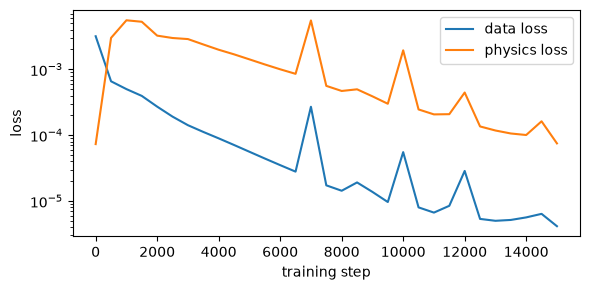

In [8]:
hist = np.array(history)
plt.figure(figsize=(6, 3))
plt.semilogy(hist[:, 0], hist[:, 1], label="data loss")
plt.semilogy(hist[:, 0], hist[:, 2], label="physics loss")
plt.xlabel("training step"); plt.ylabel("loss"); plt.legend()
plt.tight_layout(); plt.show()

## Compare against the solver

The test that matters: does the network reproduce the reference everywhere,
including the points it never saw?

In [9]:
X_eval = torch.tensor(X_all, dtype=torch.float32, device=device)
with torch.no_grad():
    T_pred_hat = pinn(X_eval).cpu().numpy().reshape(T_hat.shape)
T_pred = to_physical(T_pred_hat)

err = np.abs(T_pred - Ts)
print(f"mean absolute error : {err.mean():.3f} degC")
print(f"max  absolute error : {err.max():.3f} degC")

mean absolute error : 0.106 degC
max  absolute error : 109.204 degC


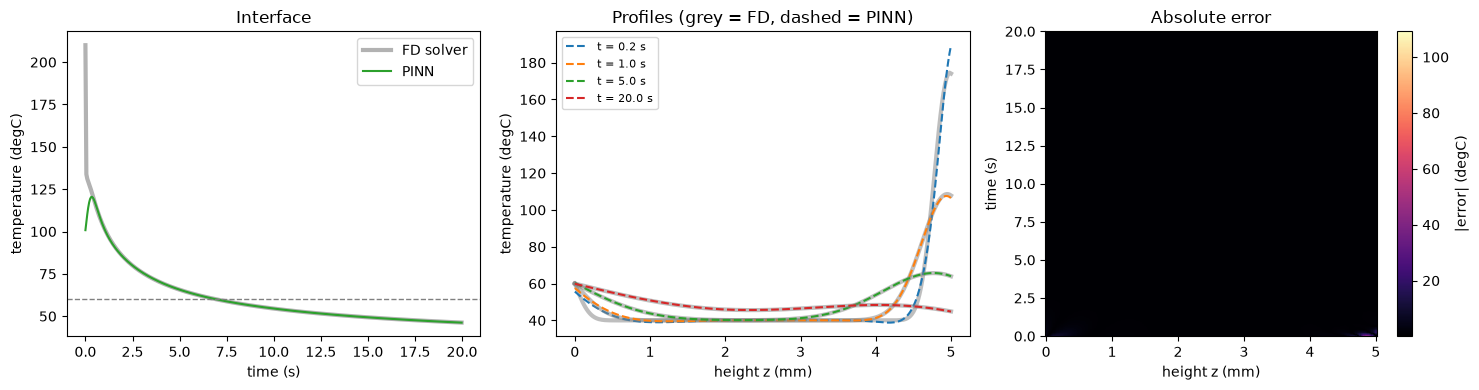

In [10]:
i_iface = np.argmin(np.abs(z - (H - LH)))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(ts, Ts[:, i_iface], color="tab:grey", lw=3, alpha=0.6, label="FD solver")
ax[0].plot(ts, T_pred[:, i_iface], color="tab:green", label="PINN")
ax[0].axhline(Tg, ls="--", color="grey", lw=1)
ax[0].set_xlabel("time (s)"); ax[0].set_ylabel("temperature (degC)")
ax[0].set_title("Interface"); ax[0].legend()

for t_want in [0.2, 1.0, 5.0, 20.0]:
    j = np.argmin(np.abs(ts - t_want))
    l, = ax[1].plot(z*1e3, Ts[j], color="tab:grey", alpha=0.5, lw=3)
    ax[1].plot(z*1e3, T_pred[j], ls="--", label=f"t = {ts[j]:.1f} s")
ax[1].set_xlabel("height z (mm)"); ax[1].set_ylabel("temperature (degC)")
ax[1].set_title("Profiles (grey = FD, dashed = PINN)"); ax[1].legend(fontsize=8)

im = ax[2].pcolormesh(z*1e3, ts, err, shading="auto", cmap="magma")
plt.colorbar(im, ax=ax[2], label="|error| (degC)")
ax[2].set_xlabel("height z (mm)"); ax[2].set_ylabel("time (s)")
ax[2].set_title("Absolute error")

plt.tight_layout(); plt.show()

## Time above $T_g$

The quantity that actually matters for interlayer bonding. If the PINN
gets the field right but this wrong, the field accuracy was measuring the
wrong thing.

In [ ]:
def time_above(t, series, thresh):
    return float(np.trapezoid((series > thresh).astype(float), t))

fd_tweld   = time_above(ts, Ts[:, i_iface], Tg)
pinn_tweld = time_above(ts, T_pred[:, i_iface], Tg)

print(f"FD solver : {fd_tweld:.3f} s")
print(f"PINN      : {pinn_tweld:.3f} s")
print(f"error     : {abs(pinn_tweld - fd_tweld)/fd_tweld*100:.2f} %")

## Things to try next

1. **Drop the data loss entirely** (`loss = loss_phys` plus initial and boundary condition terms). That is a true forward solve with no reference data — harder, and the step that proves the physics is doing the work.
2. **Sweep `lambda_phys`** over several orders of magnitude and plot the final error. The sensitivity is worth knowing before real data arrives.
3. **Learn an unknown parameter.** Make `h` a `nn.Parameter`, hide its true value from the network, and see whether training recovers it from the temperature data. This is stage 3 of the plan, and structurally identical to Task 2 of the oscillator demo.
4. **Add print settings as inputs** — feed `(z, t, T_nozzle, layer_height)` using `data/sweep.npz`. That is stage 2.
5. **Swap in the FEA.** Replace the loading cell with Digambar's output. Everything downstream should work unchanged.
